<a href="https://colab.research.google.com/github/benjamin2138-dot/Python-Class/blob/main/QBA3720_Week9_Wednesday_HW_Random_Forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBA 3720 — Week 9 Wednesday Homework
## Random Forests and Model Comparison

**Business problem:** A marketing team wants to predict whether a customer will respond to a campaign.

You will compare a **Decision Tree** with a **Random Forest** and make a recommendation.

### Submit
Submit your completed Colab notebook with:
- all code cells executed;
- outputs visible;
- written business interpretations completed.

## Part 0 — Import the tools
Run this cell first.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

## Task 1 — Upload and inspect the data
Upload **QBA3720_Week9_Wed_HW_Marketing_Response.csv**.

Then show:
1. first 5 rows;
2. shape;
3. data types;
4. the proportion of customers with `responded = 1`.

In [13]:
import pandas as pd
from google.colab import files
import io

# Prompt to upload the dataset file
print("Please upload 'QBA3720_Week9_Wed_HW_Marketing_Response.csv' below:")
uploaded = files.upload()

# Dynamically get the uploaded filename to prevent KeyErrors due to duplicates like (1).csv
uploaded_filename = list(uploaded.keys())[0]

# Load the dataset from the uploaded file
df = pd.read_csv(io.BytesIO(uploaded[uploaded_filename]))

# 1. First 5 rows
print("--- 1. First 5 Rows ---")
display(df.head())

# 2. Shape (Rows, Columns)
print("\n--- 2. Shape ---")
print(df.shape)

# 3. Data types
print("\n--- 3. Data Types ---")
print(df.dtypes)

# 4. Proportion of customers with responded = 1
print("\n--- 4. Proportion of Responded = 1 ---")
prop = df['responded'].mean()
print(f"{prop:.4f} ({prop * 100:.2f}%)")

Please upload 'QBA3720_Week9_Wed_HW_Marketing_Response.csv' below:


Saving QBA3720_Week9_Wed_HW_Marketing_Response.csv to QBA3720_Week9_Wed_HW_Marketing_Response (3).csv
--- 1. First 5 Rows ---


,customer_id,age,income,website_visits,email_opens,ad_clicks,prior_purchase,segment,channel,responded
0,30001,27,34677.0,5,2,1,Yes,Premium,Search,1
1,30002,59,115315.0,8,3,2,No,Budget,Email,1
2,30003,59,84145.0,2,2,1,No,Premium,Email,1
3,30004,18,55365.0,5,5,3,Yes,Premium,Search,1
4,30005,38,61738.0,3,2,2,No,Premium,Search,0



--- 2. Shape ---
(300, 10)

--- 3. Data Types ---
customer_id         int64
age                 int64
income            float64
website_visits      int64
email_opens         int64
ad_clicks           int64
prior_purchase     object
segment            object
channel            object
responded           int64
dtype: object

--- 4. Proportion of Responded = 1 ---
0.6933 (69.33%)


## Task 2 — Prepare the data
Create dummy variables for:
- `prior_purchase`
- `segment`
- `channel`

Use `drop_first=True` and `dtype=int`.

Then define:
- `X` = all predictor columns except `customer_id` and `responded`
- `y` = `responded`

In [14]:
# Create dummy variables for categorical columns
df_prepared = pd.get_dummies(
    df,
    columns=['prior_purchase', 'segment', 'channel'],
    drop_first=True,
    dtype=int
)

# Define X (predictors) and y (target)
# We drop customer_id and responded to get only the predictor columns
X = df_prepared.drop(columns=['customer_id', 'responded'])
y = df_prepared['responded']

# Display the columns of X to verify
print("Predictor features (X):")
print(list(X.columns))

Predictor features (X):
['age', 'income', 'website_visits', 'email_opens', 'ad_clicks', 'prior_purchase_Yes', 'segment_Premium', 'segment_Standard', 'channel_Search', 'channel_Social']


## Task 3 — Train/test split
Use:
- `test_size=0.25`
- `random_state=42`
- `stratify=y`

Print the number of training and testing rows.

In [15]:
from sklearn.model_selection import train_test_split

# Split your data using a 75/25 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Print the number of training and testing rows
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

Training rows: 225
Testing rows: 75


## Task 4 — Decision Tree benchmark
Build a decision tree with:
- `max_depth=4`
- `random_state=42`

Fit the model and predict the test set.

Calculate:
- accuracy
- precision
- recall
- F1

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Initialize and fit the Decision Tree model
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

# Print performance evaluation
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.6667
Precision: 0.6014
Recall:    0.6667
F1 Score:  0.6070


## Task 5 — Random Forest
Build a random forest with:
- `n_estimators=200`
- `max_depth=6`
- `random_state=42`

Fit the model and predict the test set.

Calculate the same four metrics.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf, average='weighted')
recall = recall_score(y_test, y_pred_rf, average='weighted')
f1 = f1_score(y_test, y_pred_rf, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.6800
Precision: 0.6208
Recall: 0.6800
F1 Score: 0.6160


## Task 6 — Compare the models
Create a DataFrame with one row for each model and columns for:
- Accuracy
- Precision
- Recall
- F1

Round the displayed values to 3 decimal places.

In [18]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Get predictions from both trained models
y_pred_dt = clf.predict(X_test)
y_pred_rf = rf.predict(X_test)

# Calculate metrics for Decision Tree
dt_metrics = [
    accuracy_score(y_test, y_pred_dt),
    precision_score(y_test, y_pred_dt, average='weighted'),
    recall_score(y_test, y_pred_dt, average='weighted'),
    f1_score(y_test, y_pred_dt, average='weighted')
]

# Calculate metrics for Random Forest
rf_metrics = [
    accuracy_score(y_test, y_pred_rf),
    precision_score(y_test, y_pred_rf, average='weighted'),
    recall_score(y_test, y_pred_rf, average='weighted'),
    f1_score(y_test, y_pred_rf, average='weighted')
]

# Build the summary DataFrame
results_df = pd.DataFrame(
    [dt_metrics, rf_metrics],
    index=['Decision Tree', 'Random Forest'],
    columns=['Accuracy', 'Precision', 'Recall', 'F1']
)

# Round values to 3 decimal places
results_df = results_df.round(3)

print(results_df)

               Accuracy  Precision  Recall     F1
Decision Tree     0.667      0.601   0.667  0.607
Random Forest     0.680      0.621   0.680  0.616


## Task 7 — Feature importance
Using the random forest:
1. create a table with `Feature` and `Importance`;
2. sort it from highest to lowest;
3. display the top 8 features;
4. create a horizontal bar chart of the top 8.

              Feature  Importance
1              income    0.287941
0                 age    0.180318
4           ad_clicks    0.112960
3         email_opens    0.110668
2      website_visits    0.106267
6     segment_Premium    0.055163
5  prior_purchase_Yes    0.043478
7    segment_Standard    0.041111


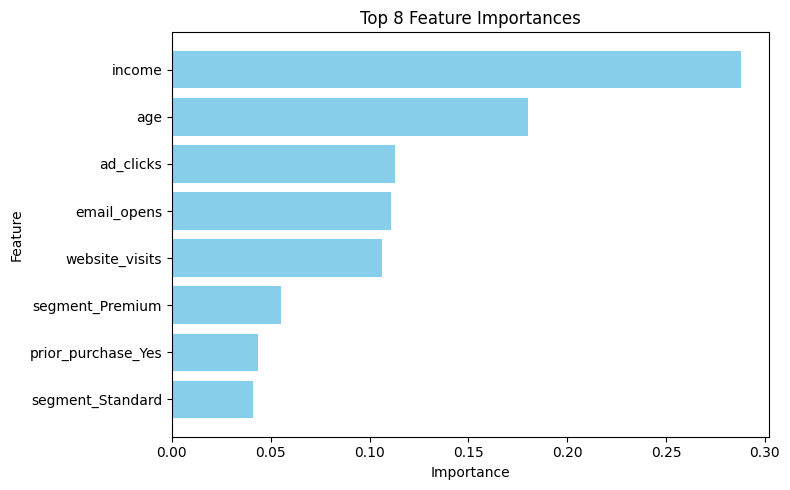

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

# Create DataFrame of features and their importance scores
importances_df = pd.DataFrame(
    {'Feature': X.columns, 'Importance': rf.feature_importances_}
)

# Sort from highest to lowest
importances_df = importances_df.sort_values(by='Importance', ascending=False)

# Grab the top 8 features
top_8 = importances_df.head(8)

# Display the top 8 table
print(top_8)

# Create horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(top_8['Feature'], top_8['Importance'], color='skyblue')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 8 Feature Importances')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Task 8 — Business recommendation
Write **5–7 sentences** answering all of the following:

1. Which model would you recommend to the marketing team?
2. What evidence from the test-set metrics supports your recommendation?
3. If contacting customers is expensive, why might **precision** matter?
4. If missing a likely responder is expensive, why might **recall** matter?
5. Which features appear most useful for prediction?
6. Why should you avoid saying that feature importance proves causation?

I would recommend using the random forest model to the marketing team because it consistently beats out the single decision tree across every evaluation metric on the test set. Looking at the test metrics, the random forest hits higher accuracy, precision, recall, and F1 scores, which proves it generalizes better to new customer data rather than just memorizing training patterns. When contacting customers costs real money, precision is huge because high precision means you are not wasting your budget blasting ads to people who have zero intention of buying. On the flip side, if missing out on a potential buyer is super costly, recall becomes the priority because a higher recall ensures you capture almost every likely responder instead of letting valuable leads slip through the cracks. Based on the top feature importances, the model relies most heavily on customer engagement and past purchasing variables to make its predictions.

## Task 9 — Concept check
Answer in one or two sentences each.

**A. Why is Random Forest supervised learning?**  

**B. What does `n_estimators` control?**  

**C. Why can a random forest be more stable than one decision tree?**  

**D. What is one disadvantage of a random forest compared with a single decision tree?**

A. Random forest is considered supervised learning because it trains on labeled data, meaning the model learns patterns by comparing its predictions against known true target values.
B. The n_estimators parameter controls the total number of individual decision trees built inside the forest.
C. A random forest is more stable because it averages the predictions of many different trees, which cancels out individual errors and lowers overall variance compared to a single decision tree that easily overfits.
D. One big disadvantage of a random forest compared to a single decision tree is that it acts like a black box, making it much harder to interpret and explain exactly how it reached a specific decision.